# Soluções candidatas para maior `salary_usd`

Um ciclo do laço de `ciclos_otimizacao.png`: **DAMICORE → modelo probabilístico → soluções candidatas → solução escolhida**, usando **apenas o dataset do quartil** (`my_datasets/salary_dataset_q1_main.csv`, 1250 linhas).

- Os clusters de colunas vêm dos arquivos `my_datasets/salary_dataset_q1_cluster0..6.csv`, que são recortes desse mesmo dataset.
- Seleção: como todas as linhas já são do quartil superior, o ciclo seleciona dentro dele as 25% mais bem pagas (coluna `top`).
- Só colunas acionáveis entram na solução; as de consequência ficam fora.
- Rode a partir da raiz do repositório, no ambiente `dami`.

In [1]:
from itertools import product
from pathlib import Path

import pandas as pd

data_dir = Path("my_datasets")
out_dir = data_dir / "salary_report"
out_dir.mkdir(exist_ok=True)
target = "salary_usd"

# Columns that describe an outcome (or the objective itself) stay out of a solution.
not_actionable = {
    "salary_usd",
    "salary_currency",
    "bonus_pct",
    "equity_offered_pct",
    "interviews_to_offer",
    "job_satisfaction_score",
    "fears_ai_automation_score",
}
numeric_actionable = [
    "years_experience",
    "ai_tools_hours_per_week",
    "upskilling_hours_per_month",
    "team_size",
    "certifications_count",
    "weekly_hours",
]
shrinkage = 50  # weight, in rows, of the independent-columns estimate
min_value_rows = 30  # a value needs this many rows before it can enter a solution
blocks_per_cluster = 3

main = pd.read_csv(data_dir / "salary_dataset_q1_main.csv")
cluster_files = sorted(data_dir.glob("salary_dataset_q1_cluster[0-9].csv"))
cluster_columns = {i: list(pd.read_csv(f, nrows=0).columns) for i, f in enumerate(cluster_files)}

# The cluster files are column subsets of this same quartile dataset, row for row.
for f, cols in zip(cluster_files, cluster_columns.values()):
    assert pd.read_csv(f).equals(main[cols])

# Selection step of the cycle: the best quarter of the current population (the quartile itself).
selected_fraction = 0.25
threshold = main[target].quantile(1 - selected_fraction)
main["top"] = main[target] >= threshold
base_rate = main["top"].mean()
base_odds = base_rate / (1 - base_rate)

decision = {c: [n for n in cols if n not in not_actionable] for c, cols in cluster_columns.items()}
print(
    f"{len(main)} linhas no quartil, {int(main['top'].sum())} selecionadas (salary_usd >= "
    f"{threshold:,.0f})"
)
decision

1250 linhas no quartil, 313 selecionadas (salary_usd >= 194,051)


{0: ['job_title',
  'experience_level',
  'industry',
  'education_level',
  'primary_language'],
 1: ['employment_type'],
 2: ['company_size', 'company_location', 'employee_residence', 'remote_ratio'],
 3: ['years_experience',
  'ai_tools_hours_per_week',
  'upskilling_hours_per_month'],
 4: ['has_ml_in_title',
  'manages_people',
  'uses_ai_tools_daily',
  'switched_jobs_last_year'],
 5: ['team_size', 'certifications_count'],
 6: ['weekly_hours']}

## Modelo probabilístico por cluster

Para cada cluster, duas tabelas com a mesma regra (frequência do bloco ÷ total de linhas): `p_bloco_topo` nas linhas selecionadas e `p_bloco` no quartil inteiro. Por Bayes, `P(selecionada | bloco) = 0,25 · p_bloco_topo / p_bloco`.

Como a amostra é pequena, blocos com poucas linhas são puxados para a estimativa por colunas independentes dentro do cluster (`p_indep`), com peso de 50 linhas, e um valor só pode entrar na solução se aparecer em pelo menos 30 linhas (`elegivel`). As colunas numéricas viram três faixas com cortes do próprio quartil.

In [2]:
def to_bands(column: pd.Series) -> pd.Series:
    """Split a numeric column into three bands using cuts from the whole dataset."""
    low, high = column.quantile([1 / 3, 2 / 3])
    labels = {
        0: f"baixo (até {low:.3g})",
        1: f"médio ({low:.3g} a {high:.3g})",
        2: f"alto (acima de {high:.3g})",
    }
    return ((column > low).astype(int) + (column > high).astype(int)).map(labels)


model = main.copy()
for name in numeric_actionable:
    model[name] = to_bands(main[name])
for cols in decision.values():
    for name in cols:
        model[name] = model[name].astype(str)


def odds(p):
    return p / (1 - p)


def cluster_table(cluster: int) -> pd.DataFrame:
    cols = decision[cluster]
    table = (
        model.groupby(cols)
        .agg(
            n=("top", "size"),
            n_top=("top", "sum"),
            salario_mediano=(target, "median"),
            salario_maximo=(target, "max"),
        )
        .reset_index()
    )
    table["p_bloco"] = table["n"] / len(model)
    table["p_bloco_topo"] = table["n_top"] / model["top"].sum()
    table["p_topo_bruto"] = table["n_top"] / table["n"]
    # Independent-columns estimate inside the cluster: product of each column's odds ratio.
    ratio = pd.Series(1.0, index=table.index)
    table["elegivel"] = True
    for name in cols:
        by_value = model.groupby(name)["top"].agg(["size", "sum"])
        table["elegivel"] &= table[name].map(by_value["size"] >= min_value_rows)
        p_value = (by_value["sum"] + base_rate) / (by_value["size"] + 1)
        ratio *= table[name].map(odds(p_value) / base_odds)
    table["p_indep"] = base_odds * ratio / (1 + base_odds * ratio)
    # Rare blocks lean on the independent estimate; well-supported blocks keep their own frequency.
    table["p_topo"] = (table["n_top"] + shrinkage * table["p_indep"]) / (table["n"] + shrinkage)
    table["razao_chance"] = odds(table["p_topo"]) / base_odds
    table.insert(0, "cluster", cluster)
    return table.sort_values("p_topo", ascending=False, ignore_index=True)


tables = {c: cluster_table(c) for c in decision}
for t in tables.values():
    assert abs(t["p_bloco"].sum() - 1) < 1e-9 and abs(t["p_bloco_topo"].sum() - 1) < 1e-9
    assert abs((t["p_topo_bruto"] * t["p_bloco"]).sum() - base_rate) < 1e-9

# Blocks built on a value with too few rows are kept in the table but cannot be chosen.
best = {c: t[t["elegivel"]].head(blocks_per_cluster) for c, t in tables.items()}
for c, t in best.items():
    print(
        f"cluster {c}: {len(tables[c])} blocos distintos, {int(tables[c]['elegivel'].sum())} "
        f"elegíveis"
    )
    display(
        t[
            decision[c]
            + [
                "n",
                "n_top",
                "p_bloco_topo",
                "p_bloco",
                "p_topo",
                "salario_mediano",
                "salario_maximo",
            ]
        ]
    )

cluster 0: 923 blocos distintos, 817 elegíveis


,job_title,experience_level,industry,education_level,primary_language,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,Data Science Manager,Executive,Finance,Masters,Python,1,1,0.003195,0.0008,0.792069,216932.0,216932
1,Data Science Manager,Executive,Technology,PhD,Python,1,1,0.003195,0.0008,0.786898,338452.0,338452
2,Data Science Manager,Executive,Finance,Masters,R,1,0,0.000000,0.0008,0.750490,159896.0,159896


cluster 1: 4 blocos distintos, 3 elegíveis


,employment_type,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,Full-time,1114,283,0.904153,0.8912,0.254039,165020.5,372347
1,Contract,89,22,0.070288,0.0712,0.247204,162938.0,329944
2,Freelance,38,8,0.025559,0.0304,0.211107,154512.5,276910


cluster 2: 139 blocos distintos, 91 elegíveis


...

,has_ml_in_title,manages_people,uses_ai_tools_daily,switched_jobs_last_year,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,True,True,True,True,57,30,0.095847,0.0456,0.501862,198756.0,352584
1,True,True,False,True,6,5,0.015974,0.0048,0.464581,207437.5,244462
2,True,True,False,False,15,9,0.028754,0.0120,0.457881,198200.0,271576


cluster 5: 9 blocos distintos, 9 elegíveis


,team_size,certifications_count,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,alto (acima de 9),alto (acima de 3),57,17,0.054313,0.0456,0.289627,169616.0,267056
1,médio (7 a 9),alto (acima de 3),56,16,0.051118,0.0448,0.283685,173660.0,309068
2,baixo (até 7),alto (acima de 3),81,22,0.070288,0.0648,0.277443,164931.0,303045


cluster 6: 3 blocos distintos, 3 elegíveis


,weekly_hours,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,alto (acima de 48.3),411,120,0.383387,0.3288,0.291960,171764.0,372347
1,médio (42.9 a 48.3),417,103,0.329073,0.3336,0.247003,162938.0,361230
2,baixo (até 42.9),422,90,0.287540,0.3376,0.213279,158621.0,340887


## Soluções candidatas

Combinações dos 3 melhores blocos elegíveis de cada cluster. A pontuação é o produto das razões de chance dos blocos e serve só para ordenar: os clusters são tratados como independentes entre si, então ela não é uma probabilidade.

In [3]:
def describe(cluster: int, row: pd.Series) -> str:
    return "; ".join(f"{name}={row[name]}" for name in decision[cluster])


records = []
for choice in product(*(range(len(best[c])) for c in decision)):
    rows = {c: best[c].iloc[i] for c, i in zip(decision, choice)}
    score = 1.0
    for row in rows.values():
        score *= row["razao_chance"]
    record = {"pontuacao": score}
    record.update({f"posicao_{c}": i + 1 for c, i in zip(decision, choice)})
    record.update({f"bloco_{c}": describe(c, row) for c, row in rows.items()})
    records.append(record)
candidates = pd.DataFrame(records).sort_values("pontuacao", ascending=False, ignore_index=True)
candidates.insert(0, "candidata", candidates.index + 1)
candidates.insert(
    2, "pontuacao_relativa", candidates["pontuacao"] / candidates["pontuacao"].iloc[0]
)

print(f"{len(candidates)} candidatas")
candidates.head(10)[["candidata", "pontuacao_relativa"] + [f"posicao_{c}" for c in decision]]

2187 candidatas


,candidata,pontuacao_relativa,posicao_0,posicao_1,posicao_2,posicao_3,posicao_4,posicao_5,posicao_6
0,1,1.000000,1,1,1,1,1,1,1
1,2,0.993673,1,1,2,1,1,1,1
2,3,0.971360,1,1,1,1,1,2,1
3,4,0.969362,2,1,1,1,1,1,1
4,5,0.965215,1,1,2,1,1,2,1
5,6,0.964257,1,2,1,1,1,1,1
6,7,0.963230,2,1,2,1,1,1,1
7,8,0.958156,1,2,2,1,1,1,1
8,9,0.941778,1,1,1,1,1,3,1
9,10,0.941600,2,1,1,1,1,2,1


## Solução escolhida

A candidata de maior pontuação, aberta coluna a coluna. `p_topo` é a parcela das linhas com aquele valor que está entre as selecionadas (a base é 25%). `peso` vem da diferença entre o melhor e o pior valor da coluna nessa parcela (forte: mais de 15 pontos; quase nenhum: até 5).

In [4]:
chosen = {c: best[c].iloc[0] for c in decision}

# Effect of each column alone: shows which parts of the chosen blocks actually carry weight.
effects = []
for c in decision:
    for name in decision[c]:
        by_value = model.groupby(name).agg(
            n=("top", "size"),
            p_topo=("top", "mean"),
            mediana=(target, "median"),
            maximo=(target, "max"),
        )
        solid = by_value[by_value["n"] >= 30]
        value = chosen[c][name]
        effects.append(
            {
                "cluster": c,
                "coluna": name,
                "valor_escolhido": value,
                "linhas": int(by_value.at[value, "n"]),
                "p_topo": by_value.at[value, "p_topo"],
                "salario_mediano": by_value.at[value, "mediana"],
                "salario_maximo": by_value.at[value, "maximo"],
                "melhor_valor": solid["p_topo"].idxmax(),
                "p_topo_melhor": solid["p_topo"].max(),
                "p_topo_pior": solid["p_topo"].min(),
            }
        )
solution = pd.DataFrame(effects)
solution["amplitude"] = solution["p_topo_melhor"] - solution["p_topo_pior"]
solution["peso"] = pd.cut(
    solution["amplitude"], [-1, 0.05, 0.15, 1], labels=["quase nenhum", "moderado", "forte"]
).astype(str)
solution

,cluster,coluna,valor_escolhido,linhas,p_topo,salario_mediano,salario_maximo,melhor_valor,p_topo_melhor,p_topo_pior,amplitude,peso
0,0,job_title,Data Science Manager,75,0.386667,178467.0,372347,Data Science Manager,0.386667,0.131148,0.255519,forte
1,0,experience_level,Executive,148,0.554054,201475.5,361230,Executive,0.554054,0.068493,0.485561,forte
2,0,industry,Finance,280,0.325000,172485.0,352584,Finance,0.325000,0.029412,0.295588,forte
3,0,education_level,Masters,506,0.260870,167042.0,361230,PhD,0.303665,0.170732,0.132933,moderado
4,0,primary_language,Python,781,0.261204,165093.0,372347,Scala,0.298246,0.225664,0.072582,moderado
5,1,employment_type,Full-time,1114,0.254039,165020.5,372347,Full-time,0.254039,0.210526,0.043513,quase nenhum
6,2,company_size,L,439,0.337130,171764.0,372347,L,0.337130,0.138122,0.199008,forte
7,2,company_location,US,851,0.297297,170473.0,372347,US,0.297297,0.114754,0.182543,forte
8,2,employee_residence,US,807,0.286245,169456.0,372347,US,0.286245,0.118644,0.167601,forte
9,2,remote_ratio,50,379,0.271768,166025.0,352584,100,0.280000,0.211694,0.068306,moderado


## Conferência com linhas reais

Todo valor em dólar abaixo é mediana de linhas reais do quartil, agrupadas por quanto se parecem com a solução.

In [5]:
def summarize(groups: pd.Series, name: str) -> pd.DataFrame:
    return (
        main.groupby(groups, observed=True)
        .agg(
            linhas=(target, "size"),
            salario_mediano=(target, "median"),
            salario_maximo=(target, "max"),
            no_topo=("top", "mean"),
        )
        .reset_index(names=name)
    )


# Whole blocks: how many of the 7 chosen blocks each real row matches.
block_hits = pd.DataFrame(
    {c: (model[decision[c]] == chosen[c][decision[c]].values).all(axis=1) for c in decision}
)
block_check = summarize(block_hits.sum(axis=1), "blocos_casados")

# Strong columns only: how many of them each real row matches.
strong = solution[solution["peso"] == "forte"]
strong_hits = pd.DataFrame(
    {r.coluna: model[r.coluna] == r.valor_escolhido for r in strong.itertuples()}
)
strong_count = strong_hits.sum(axis=1)
# Merge the sparse ends so that every group has at least min_value_rows rows.
low = min(v for v in range(len(strong) + 1) if (strong_count <= v).sum() >= min_value_rows)
high = max(v for v in range(len(strong) + 1) if (strong_count >= v).sum() >= min_value_rows)
labels = {v: str(v) for v in range(low, high + 1)}
labels[low], labels[high] = (
    f"0 a {low}" if low else "0",
    f"{high} a {len(strong)}" if high < len(strong) else str(high),
)
strong_check = summarize(strong_count.clip(low, high), "colunas_fortes_casadas")
strong_check["colunas_fortes_casadas"] = strong_check["colunas_fortes_casadas"].map(labels)

display(block_check)
display(strong_check)

,blocos_casados,linhas,salario_mediano,salario_maximo,no_topo
0,0,71,154670.0,329944,0.169014
1,1,671,157951.0,361230,0.207154
2,2,435,168531.0,372347,0.264368
3,3,68,202401.0,303045,0.617647
4,4,4,244630.0,352584,1.000000
5,5,1,213850.0,213850,1.000000


,colunas_fortes_casadas,linhas,salario_mediano,salario_maximo,no_topo
0,0,64,140131.5,207507,0.015625
1,1,115,142929.0,229764,0.034783
2,2,354,154344.0,282289,0.096045
3,3,347,162174.0,276550,0.216138
4,4,221,186976.0,372347,0.447964
5,5,101,207927.0,361230,0.603960
6,6 a 8,48,219716.0,352584,0.812500


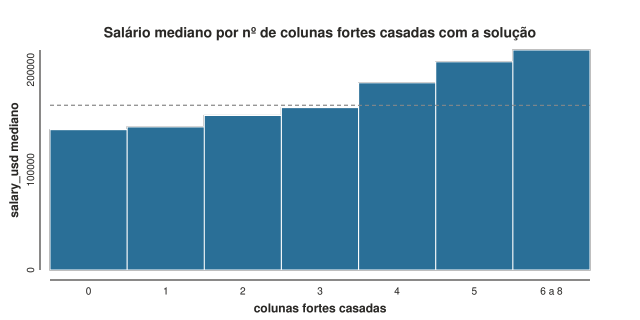

In [6]:
import toyplot

canvas = toyplot.Canvas(width=640, height=320)
axes = canvas.cartesian(
    label="Salário mediano por nº de colunas fortes casadas com a solução",
    xlabel="colunas fortes casadas",
    ylabel="salary_usd mediano",
)
axes.bars(strong_check["salario_mediano"].to_numpy(), color="#2a6f97")
axes.x.ticks.locator = toyplot.locator.Explicit(
    labels=list(strong_check["colunas_fortes_casadas"].astype(str))
)
axes.hlines(main[target].median(), style={"stroke": "#888", "stroke-dasharray": "4,3"})
canvas

## Arquivos do report

Grava os CSVs e o `report.pdf` em `my_datasets/salary_report/`.

In [7]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import mm
from reportlab.platypus import Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

pd.concat(tables.values()).to_csv(out_dir / "blocos_por_cluster.csv", index=False)
candidates.to_csv(out_dir / "solucoes_candidatas.csv", index=False)
solution.to_csv(out_dir / "solucao_escolhida.csv", index=False)
strong_check.to_csv(out_dir / "conferencia_colunas_fortes.csv", index=False)
block_check.to_csv(out_dir / "conferencia_blocos.csv", index=False)

styles = getSampleStyleSheet()
body, small = styles["BodyText"], styles["BodyText"].clone("small", fontSize=8, leading=10)


def money(value: float) -> str:
    return f"US$ {value:,.0f}".replace(",", ".")


def pct(value: float) -> str:
    return f"{value:.0%}"


def pdf_table(rows: list[list[str]], widths: list[float]) -> Table:
    table = Table(
        [[Paragraph(str(cell), small) for cell in row] for row in rows],
        colWidths=[w * mm for w in widths],
        repeatRows=1,
    )
    table.setStyle(
        TableStyle(
            [
                ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e6eef3")),
                ("LINEBELOW", (0, 0), (-1, -1), 0.3, colors.HexColor("#b8c4cc")),
                ("VALIGN", (0, 0), (-1, -1), "TOP"),
            ]
        )
    )
    return table


top_group = strong_check.iloc[-1]
strong_names = ", ".join(strong["coluna"])
story = [
    Paragraph("Solução escolhida para maior salary_usd", styles["Title"]),
    Paragraph(
        f"Ciclo aplicado uma vez: DAMICORE (7 clusters de colunas) → modelo probabilístico por "
        f"cluster → "
        f"{len(candidates)} soluções candidatas → solução escolhida. Base: só o dataset do "
        f"quartil, {len(main)} linhas. "
        f"Seleção dentro dele: as {int(main['top'].sum())} linhas mais bem pagas (salary_usd a "
        f"partir de {money(threshold)}).",
        body,
    ),
    Spacer(1, 4 * mm),
    Paragraph(
        f"Nas linhas reais que casam com {top_group['colunas_fortes_casadas']} das {len(strong)} "
        f"colunas de peso forte "
        f"da solução, o salário mediano é {money(top_group['salario_mediano'])} e "
        f"{pct(top_group['no_topo'])} estão entre "
        f"as selecionadas ({int(top_group['linhas'])} linhas); o maior salário desse grupo é "
        f"{money(top_group['salario_maximo'])}. "
        f"No quartil inteiro, o maior salary_usd é {money(main[target].max())} e a mediana é "
        f"{money(main[target].median())}.",
        body,
    ),
    Spacer(1, 4 * mm),
    Paragraph("Solução escolhida, coluna a coluna", styles["Heading2"]),
    pdf_table(
        [["Cl.", "Coluna", "Valor escolhido", "Linhas", "Selec.", "Mediana", "Máximo", "Peso"]]
        + [
            [
                r.cluster,
                r.coluna,
                r.valor_escolhido,
                r.linhas,
                pct(r.p_topo),
                money(r.salario_mediano),
                money(r.salario_maximo),
                r.peso,
            ]
            for r in solution.itertuples()
        ],
        [12, 40, 38, 13, 13, 23, 23, 17],
    ),
    Spacer(1, 4 * mm),
    Paragraph("Conferência com linhas reais", styles["Heading2"]),
    Paragraph(f"Colunas de peso forte: {strong_names}.", small),
    pdf_table(
        [
            [
                "Colunas fortes casadas",
                "Linhas",
                "Salário mediano",
                "Maior salário",
                "Entre as selecionadas",
            ]
        ]
        + [
            [
                r.colunas_fortes_casadas,
                r.linhas,
                money(r.salario_mediano),
                money(r.salario_maximo),
                pct(r.no_topo),
            ]
            for r in strong_check.itertuples()
        ],
        [40, 20, 35, 35, 40],
    ),
    Spacer(1, 4 * mm),
    Paragraph("Melhor bloco de cada cluster", styles["Heading2"]),
    pdf_table(
        [["Cl.", "Bloco", "Linhas", "Selec. (bruto)", "Estim.", "Mediana", "Máximo"]]
        + [
            [
                c,
                describe(c, row),
                int(row["n"]),
                pct(row["p_topo_bruto"]),
                pct(row["p_topo"]),
                money(row["salario_mediano"]),
                money(row["salario_maximo"]),
            ]
            for c, row in chosen.items()
        ],
        [12, 76, 13, 20, 17, 21, 21],
    ),
    Spacer(1, 4 * mm),
    Paragraph("As 10 melhores candidatas", styles["Heading2"]),
    Paragraph(
        "Posição do bloco usado em cada cluster (1 = melhor bloco do cluster). Pontuação relativa "
        "à escolhida.",
        small,
    ),
    pdf_table(
        [["Candidata", "Pontuação"] + [f"C{c}" for c in decision]]
        + [
            [r["candidata"], pct(r["pontuacao_relativa"])] + [r[f"posicao_{c}"] for c in decision]
            for _, r in candidates.head(10).iterrows()
        ],
        [20, 22] + [14] * len(decision),
    ),
    Spacer(1, 4 * mm),
    Paragraph("Ressalvas", styles["Heading2"]),
    Paragraph(
        "Os números descrevem associação nas linhas observadas, não efeito causal. Tudo é medido "
        "dentro do quartil: a "
        "solução diz o que distingue os salários mais altos entre quem já ganha bem, não o que "
        "leva alguém ao quartil. "
        f"A amostra é pequena ({int(main['top'].sum())} linhas selecionadas), então valores com "
        f"menos de {min_value_rows} linhas "
        "não entram na solução e blocos raros são puxados para o efeito de cada coluna isolada. "
        "Colunas de consequência "
        "(bônus, equity, satisfação, medo de automação, nº de entrevistas, moeda) ficaram fora. A "
        "conferência usa as mesmas "
        "linhas que geraram a solução. Colunas com peso 'quase nenhum' podem assumir outro valor "
        "sem mudar o resultado. "
        f"O bloco do cluster 0 existe em {int(chosen[0]['n'])} linha(s) real(is): ele vale pelo "
        f"efeito de cada coluna, não como combinação observada.",
        body,
    ),
]
SimpleDocTemplate(
    str(out_dir / "report.pdf"),
    pagesize=A4,
    leftMargin=16 * mm,
    rightMargin=16 * mm,
    topMargin=16 * mm,
    bottomMargin=16 * mm,
    title="Solução escolhida para maior salary_usd",
).build(story)
print(f"Arquivos gravados em {out_dir.resolve()}")

Arquivos gravados em /home/lobo/github/damicore/my_datasets/salary_report
